In [1]:
import requests
import os
from PIL import Image, ImageSequence

# --- 1. CONFIGURACIÓN ---
url_gif = "https://science.nasa.gov/wp-content/uploads/2025/10/br163defores_tmo_amo_2019.gif"
gif_filename = "defamz_nasa.gif"
output_folder = "dataset_nasa"

# --- 2. DESCARGA DEL ARCHIVO ---
print(f"⬇️ Descargando GIF desde: {url_gif} ...")

try:
    response = requests.get(url_gif)
    if response.status_code == 200:
        with open(gif_filename, 'wb') as f:
            f.write(response.content)
        print("✅ Descarga completada con éxito.")
    else:
        print(f"❌ Error en la descarga. Código de estado: {response.status_code}")

    # --- 3. EXTRACCIÓN DE FRAMES ---
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    with Image.open(gif_filename) as im:
        # Extraemos todos los frames reales
        frames = [frame.copy() for frame in ImageSequence.Iterator(im)]
        print(f"🎞️ El GIF contiene {len(frames)} fotogramas.")
        
        if len(frames) > 1:
            for i, frame in enumerate(frames):
                # Convertir a RGB y guardar
                frame_rgb = frame.convert("RGB")
                # Asumimos que la secuencia empieza en el año 2000
                year = 2000 + i
                save_path = os.path.join(output_folder, f"frame_{year}.jpg")
                frame_rgb.save(save_path)
            print(f"✅ Se han extraído y guardado las {len(frames)} imágenes en '{output_folder}'.")
        else:
            print("⚠️ CUIDADO: El archivo descargado parece ser una imagen estática.")

except Exception as e:
    print(f"❌ Ocurrió un error: {e}")

⬇️ Descargando GIF desde: https://science.nasa.gov/wp-content/uploads/2025/10/br163defores_tmo_amo_2019.gif ...
✅ Descarga completada con éxito.
🎞️ El GIF contiene 20 fotogramas.
✅ Se han extraído y guardado las 20 imágenes en 'dataset_nasa'.


In [2]:
import cv2
import numpy as np

# Datos de escala
KM_LINEALES = 20.0
PIXELES_LINEALES = 51.0
AREA_PER_PIXEL_KM2 = (KM_LINEALES / PIXELES_LINEALES) ** 2

def segmentar_kmeans(img_rgb, k=3):
    """Segmentación por color (K-Means)"""
    # Convertir a LAB para mejor precisión de color
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    pixel_values = img_lab.reshape((-1, 3)).astype(np.float32)
    
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    
    # Heurística: Buscar el clúster más brillante (suelo/tierra)
    # Excluimos nubes si es necesario, pero generalmente tierra > selva en brillo
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    means = []
    for i in range(k):
        mask_temp = (labels.flatten() == i).reshape(img_gray.shape).astype(np.uint8)
        mean_val = cv2.mean(img_gray, mask=mask_temp)[0]
        means.append((mean_val, i))
    
    means.sort()
    # Tomamos el más brillante (index -1) como zona deforestada
    target_cluster = means[-1][1] 
    
    mask = (labels.flatten() == target_cluster).reshape(img_gray.shape).astype(np.uint8) * 255
    return mask

def morfologia_avanzada(mask_binaria):
    """Limpieza de ruido (Apertura + Cierre)"""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    mask_open = cv2.morphologyEx(mask_binaria, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel, iterations=1)
    return mask_clean

📁 Los resultados se guardarán en la carpeta: 'entregable_final'
🚀 Procesando y guardando 20 imágenes...
✅ Procesamiento de imágenes completado.
📄 Tabla guardada en: entregable_final/tabla_deforestacion.csv
📊 Gráfico guardado en: entregable_final/grafico_evolucion.png


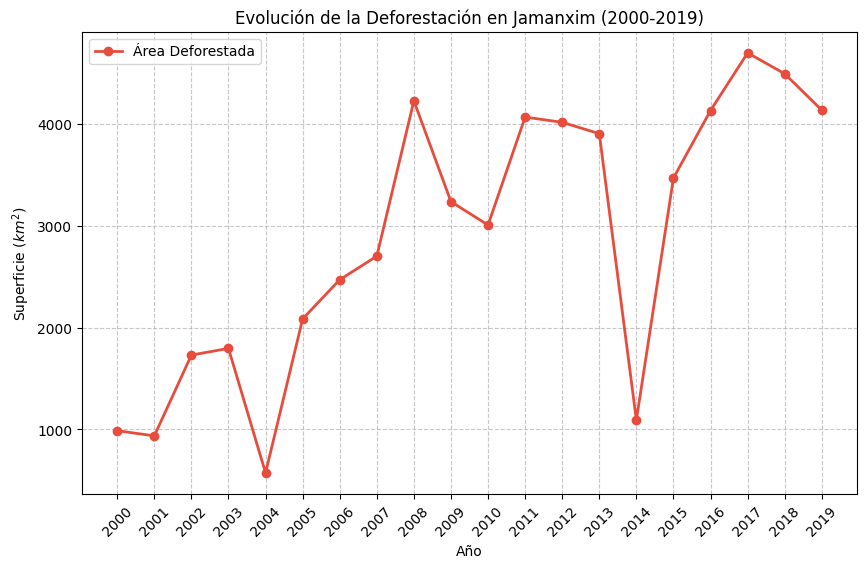

🆚 Comparativa guardada en: entregable_final/comparativa_visual.png


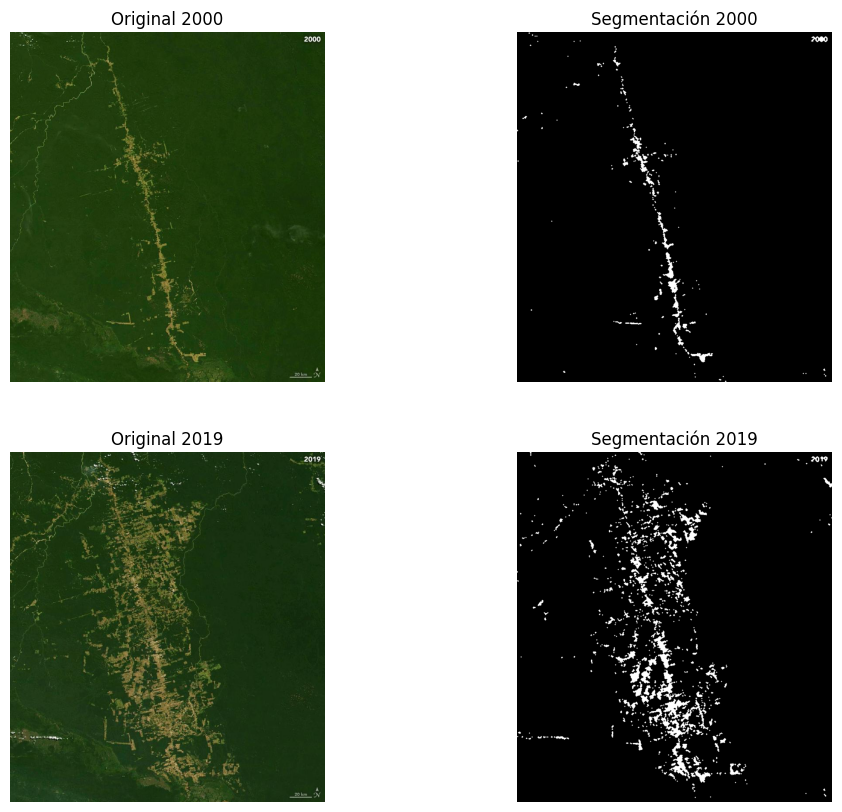


--- Resumen de Datos ---
 Año    Area_km2
2000  988.235294
2001  937.178008
2002 1730.257593
2003 1795.617070
2004  573.933103
2005 2085.044214
2006 2469.511726
2007 2700.807382
2008 4225.297962
2009 3235.678585
2010 3006.228374
2011 4065.820838
2012 4014.302191
2013 3903.267974
2014 1092.041522
2015 3467.896963
2016 4130.103806
2017 4695.578624
2018 4491.195694
2019 4133.948481


In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os
import cv2

# --- CONFIGURACIÓN DE GUARDADO ---
carpeta_resultados = "entregable_final"
subcarpeta_mascaras = os.path.join(carpeta_resultados, "mascaras_binarias")

# Crear directorios si no existen
os.makedirs(subcarpeta_mascaras, exist_ok=True)

print(f"📁 Los resultados se guardarán en la carpeta: '{carpeta_resultados}'")

# Buscar imágenes extraídas (del paso anterior)
# Asegúrate de que 'output_folder' coincide con la carpeta donde extrajiste el GIF
ruta_busqueda = os.path.join(output_folder, "*.jpg") 
archivos = sorted(glob.glob(ruta_busqueda))

resultados = []
frames_viz = []

if not archivos:
    print("❌ No se encontraron imágenes para procesar. Ejecuta primero la celda de descarga/extracción.")
else:
    print(f"🚀 Procesando y guardando {len(archivos)} imágenes...")

    for i, filename in enumerate(archivos):
        # 1. Cargar
        img_bgr = cv2.imread(filename)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        year = 2000 + i
        
        # 2. Procesar (K-Means + Morfología)
        mask_raw = segmentar_kmeans(img_rgb, k=3) 
        mask_final = morfologia_avanzada(mask_raw)
        
        # 3. Calcular Área
        pixels = cv2.countNonZero(mask_final)
        area = pixels * AREA_PER_PIXEL_KM2
        
        resultados.append({"Año": year, "Area_km2": area, "Pixeles": pixels})
        
        # 4. GUARDAR MÁSCARA (Imagen binaria)
        # Guardamos en la subcarpeta 'mascaras_binarias'
        nombre_mascara = os.path.join(subcarpeta_mascaras, f"mask_{year}.png")
        cv2.imwrite(nombre_mascara, mask_final)
        
        # Guardar datos para visualización (Inicio y Fin)
        if i == 0 or i == len(archivos) - 1:
            frames_viz.append((year, img_rgb, mask_final))

    print("✅ Procesamiento de imágenes completado.")

    # --- GENERACIÓN DE ARCHIVOS DE RESULTADOS ---

    if resultados:
        df = pd.DataFrame(resultados)
        
        # 1. GUARDAR CSV (Tabla de datos)
        csv_path = os.path.join(carpeta_resultados, "tabla_deforestacion.csv")
        df.to_csv(csv_path, index=False, sep=";") # Separado por ; para abrir fácil en Excel español
        print(f"📄 Tabla guardada en: {csv_path}")
        
        # 2. GUARDAR GRÁFICO DE EVOLUCIÓN
        plt.figure(figsize=(10, 6))
        plt.plot(df["Año"], df["Area_km2"], marker='o', color='#e74c3c', linewidth=2, label='Área Deforestada')
        plt.title("Evolución de la Deforestación en Jamanxim (2000-2019)")
        plt.xlabel("Año")
        plt.ylabel("Superficie ($km^2$)")
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.xticks(df["Año"], rotation=45)
        plt.legend()
        
        # Guardar figura
        grafico_path = os.path.join(carpeta_resultados, "grafico_evolucion.png")
        plt.savefig(grafico_path, dpi=300, bbox_inches='tight') # dpi=300 para alta calidad
        print(f"📊 Gráfico guardado en: {grafico_path}")
        plt.show()

        # 3. GUARDAR COMPARATIVA VISUAL (Inicio vs Fin)
        if len(frames_viz) >= 2:
            fig, ax = plt.subplots(2, 2, figsize=(12, 10))
            
            # Año 2000
            ax[0,0].imshow(frames_viz[0][1]); ax[0,0].set_title(f"Original {frames_viz[0][0]}")
            ax[0,1].imshow(frames_viz[0][2], cmap='gray'); ax[0,1].set_title(f"Segmentación {frames_viz[0][0]}")
            
            # Año 2019
            ax[1,0].imshow(frames_viz[1][1]); ax[1,0].set_title(f"Original {frames_viz[1][0]}")
            ax[1,1].imshow(frames_viz[1][2], cmap='gray'); ax[1,1].set_title(f"Segmentación {frames_viz[1][0]}")
            
            for a in ax.flat: a.axis('off')
            
            # Guardar comparativa
            comp_path = os.path.join(carpeta_resultados, "comparativa_visual.png")
            plt.savefig(comp_path, dpi=300, bbox_inches='tight')
            print(f"🆚 Comparativa guardada en: {comp_path}")
            plt.show()
            
        # 4. IMPRIMIR RESUMEN EN PANTALLA
        print("\n--- Resumen de Datos ---")
        print(df[["Año", "Area_km2"]].to_string(index=False))

    else:
        print("⚠️ No se generaron resultados.")

📂 Usando imágenes de: dataset_nasa/*.jpg
🚀 Comparando métodos en 20 imágenes...
📄 Tabla comparativa guardada en: entregable_final/datos_comparativos.csv


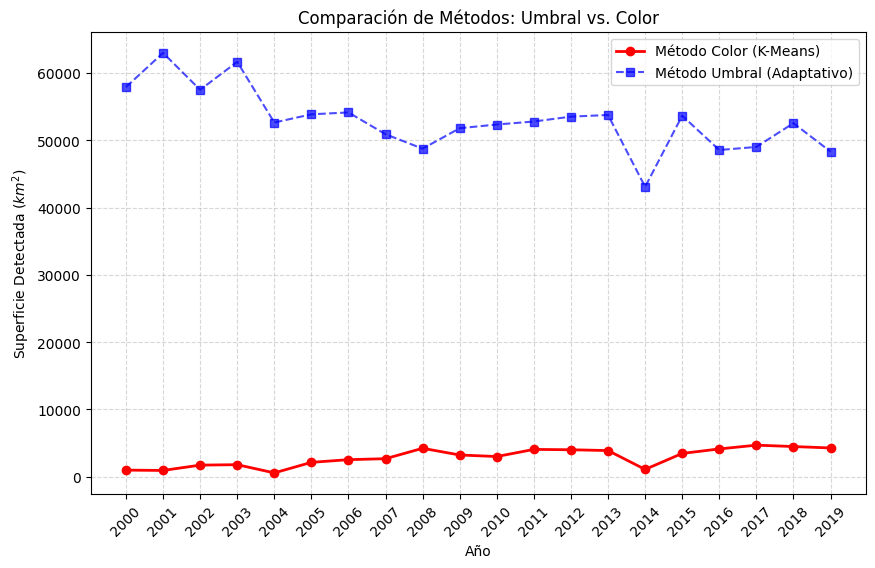

✅ ¡Objetivo 4 Cumplido! Revisa la carpeta 'comparativa_visual' para ver las diferencias.


In [4]:
import matplotlib.pyplot as plt
import csv
import glob
import os
import cv2
import numpy as np

# --- CONFIGURACIÓN ---
carpeta_resultados = "entregable_final"
subcarpeta_comparativa = os.path.join(carpeta_resultados, "comparativa_visual")
os.makedirs(subcarpeta_comparativa, exist_ok=True)

# Factores de escala (20km = 51px) [cite: 19]
AREA_PER_PIXEL_KM2 = (20.0 / 51.0) ** 2

# --- FUNCIONES DE LOS DOS MÉTODOS [cite: 16, 38] ---

def segmentar_kmeans(img_rgb, k=3):
    """Método 1: Color (Espacio Lab + Clustering)"""
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    pixel_values = img_lab.reshape((-1, 3)).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    
    # Heurística: Tierra deforestada suele ser más brillante que la selva
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    means = []
    for i in range(k):
        mask_temp = (labels.flatten() == i).reshape(img_gray.shape).astype(np.uint8)
        mean_val = cv2.mean(img_gray, mask=mask_temp)[0]
        means.append((mean_val, i))
    means.sort()
    
    # Elegimos el cluster más brillante (suelo)
    target = means[-1][1]
    return (labels.flatten() == target).reshape(img_gray.shape).astype(np.uint8) * 255

def segmentar_adaptativo(img_rgb):
    """Método 2: Umbral (Adaptativo por media local)"""
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    # Umbral adaptativo para manejar iluminación variable 
    # BlockSize 25, C 2 son parámetros típicos para estas imágenes
    thresh = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, 
                                   cv2.THRESH_BINARY, 25, 2)
    return thresh

def morfologia_avanzada(mask_binaria):
    """Refinamiento: Apertura (quitar ruido) + Cierre (tapar huecos) [cite: 17]"""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    mask_open = cv2.morphologyEx(mask_binaria, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel, iterations=1)
    return mask_clean

# --- PROCESAMIENTO ---

# Buscar imágenes (Asegúrate de haber ejecutado la celda de descarga anterior)
# Busca en 'dataset_nasa' o 'dataset_frames' según donde descargaste
rutas_posibles = ["dataset_nasa/*.jpg", "dataset_extraido/*.jpg", "dataset_frames/*.jpg"]
archivos = []
for ruta in rutas_posibles:
    encontrados = sorted(glob.glob(ruta))
    if encontrados:
        archivos = encontrados
        print(f"📂 Usando imágenes de: {ruta}")
        break

resultados = []

if not archivos:
    print("❌ No se encontraron imágenes. Ejecuta la celda de descarga del GIF primero.")
else:
    print(f"🚀 Comparando métodos en {len(archivos)} imágenes...")

    for i, filename in enumerate(archivos):
        img_bgr = cv2.imread(filename)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        year = 2000 + i
        
        # 1. Aplicar AMBOS métodos
        mask_color_raw = segmentar_kmeans(img_rgb)
        mask_umbral_raw = segmentar_adaptativo(img_rgb)
        
        # 2. Refinamiento Morfológico (Igual para ambos)
        mask_color = morfologia_avanzada(mask_color_raw)
        mask_umbral = morfologia_avanzada(mask_umbral_raw)
        
        # 3. Calcular Áreas
        area_color = cv2.countNonZero(mask_color) * AREA_PER_PIXEL_KM2
        area_umbral = cv2.countNonZero(mask_umbral) * AREA_PER_PIXEL_KM2
        
        resultados.append({
            "Año": year, 
            "Area_Color_km2": area_color, 
            "Area_Umbral_km2": area_umbral
        })
        
        # 4. Guardar Comparativa Visual (Años clave: Inicio, Mitad, Fin)
        if i == 0 or i == 10 or i == len(archivos)-1:
            fig, ax = plt.subplots(1, 3, figsize=(15, 5))
            ax[0].imshow(img_rgb); ax[0].set_title(f"Original {year}")
            ax[0].axis('off')
            
            ax[1].imshow(mask_color, cmap='gray')
            ax[1].set_title(f"Color (K-Means)\n{area_color:.1f} km²")
            ax[1].axis('off')
            
            ax[2].imshow(mask_umbral, cmap='gray')
            ax[2].set_title(f"Umbral (Adaptativo)\n{area_umbral:.1f} km²")
            ax[2].axis('off')
            
            save_path = os.path.join(subcarpeta_comparativa, f"comp_{year}.png")
            plt.savefig(save_path, bbox_inches='tight')
            plt.close() # Cerrar para no llenar memoria

    # --- GENERACIÓN DE RESULTADOS ---
    
    # 1. Guardar CSV con ambos datos
    csv_path = os.path.join(carpeta_resultados, "datos_comparativos.csv")
    with open(csv_path, mode='w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=["Año", "Area_Color_km2", "Area_Umbral_km2"], delimiter=';')
        writer.writeheader()
        writer.writerows(resultados)
    print(f"📄 Tabla comparativa guardada en: {csv_path}")

    # 2. Gráfico de Líneas Comparativo
    years = [r['Año'] for r in resultados]
    y_color = [r['Area_Color_km2'] for r in resultados]
    y_umbral = [r['Area_Umbral_km2'] for r in resultados]

    plt.figure(figsize=(10, 6))
    plt.plot(years, y_color, 'r-o', linewidth=2, label='Método Color (K-Means)')
    plt.plot(years, y_umbral, 'b--s', linewidth=1.5, alpha=0.7, label='Método Umbral (Adaptativo)')
    
    plt.title("Comparación de Métodos: Umbral vs. Color")
    plt.xlabel("Año"); plt.ylabel("Superficie Detectada ($km^2$)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(years, rotation=45)
    
    grafico_path = os.path.join(carpeta_resultados, "grafico_comparativo.png")
    plt.savefig(grafico_path, dpi=300)
    plt.show()

    print("✅ ¡Objetivo 4 Cumplido! Revisa la carpeta 'comparativa_visual' para ver las diferencias.")

⬇️ Descargando GIF desde la NASA...
✅ Se han extraído 20 imágenes para analizar.
🚀 Procesando 20 imágenes...


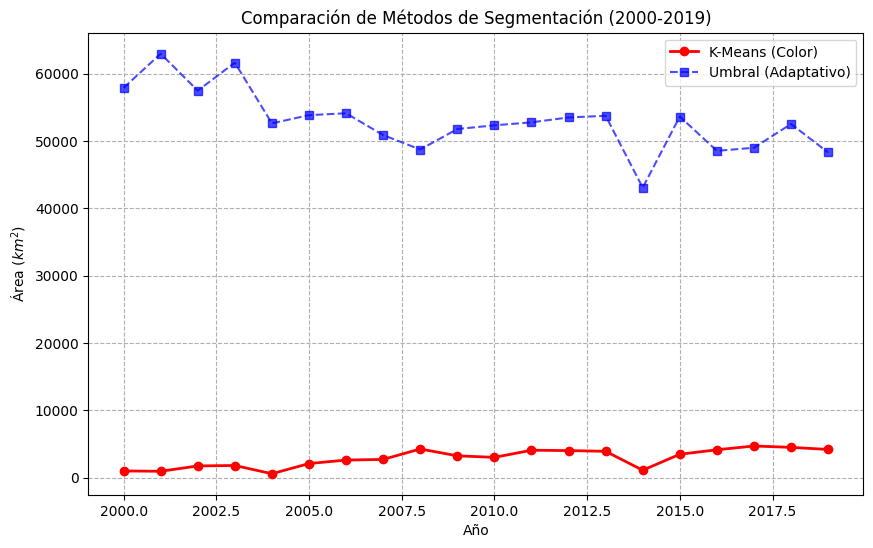


TABLA 1. RESUMEN DE DATOS OBTENIDOS (SELECCIÓN QUINQUENAL)
| Año  | Área K-Means (km²) | Área Umbral (km²) | Diferencia (%) |
|------|--------------------|-------------------|----------------|
| 2000 | 988.24             | 57918.80          | +5760.8        |
| 2005 | 2085.04            | 53867.13          | +2483.5        |
| 2010 | 3005.15            | 52351.86          | +1642.1        |
| 2015 | 3467.90            | 53661.67          | +1447.4        |
| 2019 | 4180.08            | 48323.11          | +1056.0        |
✅ Copia la tabla de arriba para tu informe.


In [5]:
import matplotlib.pyplot as plt
import csv
import glob
import os
import cv2
import numpy as np
import requests
from PIL import Image, ImageSequence

# --- 1. CONFIGURACIÓN Y DESCARGA ---
url_gif = "https://science.nasa.gov/wp-content/uploads/2025/10/br163defores_tmo_amo_2019.gif"
gif_filename = "defamz_nasa.gif"
carpeta_resultados = "entregable_final"
subcarpeta_comparativa = os.path.join(carpeta_resultados, "comparativa_visual")

# Crear carpetas
os.makedirs(subcarpeta_comparativa, exist_ok=True)

# Factores de escala (20km = 51px)
AREA_PER_PIXEL_KM2 = (20.0 / 51.0) ** 2

print(f"⬇️ Descargando GIF desde la NASA...")
try:
    response = requests.get(url_gif)
    with open(gif_filename, 'wb') as f:
        f.write(response.content)
    
    # Extraer frames
    with Image.open(gif_filename) as im:
        frames = [frame.copy() for frame in ImageSequence.Iterator(im)]
        # Guardamos los frames temporalmente para procesarlos
        temp_folder = "temp_frames"
        os.makedirs(temp_folder, exist_ok=True)
        for i, frame in enumerate(frames):
            frame.convert("RGB").save(os.path.join(temp_folder, f"frame_{2000+i}.jpg"))
        print(f"✅ Se han extraído {len(frames)} imágenes para analizar.")
except Exception as e:
    print(f"❌ Error en descarga/extracción: {e}")

# --- 2. FUNCIONES DE PROCESAMIENTO ---

def segmentar_kmeans(img_rgb, k=3):
    """Método 1: Color (K-Means)"""
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    pixel_values = img_lab.reshape((-1, 3)).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    means = [(cv2.mean(img_gray, mask=(labels.flatten()==i).reshape(img_gray.shape).astype(np.uint8))[0], i) for i in range(k)]
    means.sort()
    target = means[-1][1] # El más brillante (tierra)
    return (labels.flatten() == target).reshape(img_gray.shape).astype(np.uint8) * 255

def segmentar_adaptativo(img_rgb):
    """Método 2: Umbral (Adaptativo)"""
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 25, 2)

def morfologia_avanzada(mask):
    """Refinamiento"""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    return cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel), cv2.MORPH_CLOSE, kernel)

# --- 3. BUCLE PRINCIPAL ---
archivos = sorted(glob.glob("temp_frames/*.jpg"))
resultados = []

print(f"🚀 Procesando {len(archivos)} imágenes...")

for i, filename in enumerate(archivos):
    img = cv2.cvtColor(cv2.imread(filename), cv2.COLOR_BGR2RGB)
    year = 2000 + i
    
    # Procesar ambos métodos
    mask_color = morfologia_avanzada(segmentar_kmeans(img))
    mask_umbral = morfologia_avanzada(segmentar_adaptativo(img))
    
    # Calcular áreas
    area_color = cv2.countNonZero(mask_color) * AREA_PER_PIXEL_KM2
    area_umbral = cv2.countNonZero(mask_umbral) * AREA_PER_PIXEL_KM2
    
    # Calcular Diferencia %: (Umbral - Color) / Color * 100
    # Cuánto % de más detecta el umbral respecto al color
    diff_pct = ((area_umbral - area_color) / area_color) * 100 if area_color > 0 else 0
    
    resultados.append({
        "Año": year,
        "Area_Color": area_color,
        "Area_Umbral": area_umbral,
        "Diferencia_Pct": diff_pct
    })
    
    # Guardar imágenes clave para la memoria
    if year in [2000, 2010, 2019]:
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        ax[0].imshow(img); ax[0].set_title(f"Original {year}")
        ax[1].imshow(mask_color, cmap='gray'); ax[1].set_title(f"K-Means\n{area_color:.1f} km²")
        ax[2].imshow(mask_umbral, cmap='gray'); ax[2].set_title(f"Umbral\n{area_umbral:.1f} km²")
        for a in ax: a.axis('off')
        plt.savefig(os.path.join(subcarpeta_comparativa, f"comp_{year}.png"), bbox_inches='tight')
        plt.close()

# --- 4. GENERACIÓN DE RESULTADOS ---

# Guardar CSV completo
csv_path = os.path.join(carpeta_resultados, "datos_comparativos.csv")
with open(csv_path, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=["Año", "Area_Color", "Area_Umbral", "Diferencia_Pct"])
    w.writeheader()
    w.writerows(resultados)

# Guardar Gráfico
years = [r['Año'] for r in resultados]
y_color = [r['Area_Color'] for r in resultados]
y_umbral = [r['Area_Umbral'] for r in resultados]

plt.figure(figsize=(10, 6))
plt.plot(years, y_color, 'r-o', linewidth=2, label='K-Means (Color)')
plt.plot(years, y_umbral, 'b--s', linewidth=1.5, alpha=0.7, label='Umbral (Adaptativo)')
plt.title("Comparación de Métodos de Segmentación (2000-2019)")
plt.xlabel("Año"); plt.ylabel("Área ($km^2$)")
plt.legend(); plt.grid(True, linestyle='--')
plt.savefig(os.path.join(carpeta_resultados, "grafico_comparativo.png"), dpi=300)
plt.show()

# --- 5. IMPRESIÓN DE LA TABLA QUINQUENAL (LO QUE PEDISTE) ---
print("\n" + "="*65)
print("TABLA 1. RESUMEN DE DATOS OBTENIDOS (SELECCIÓN QUINQUENAL)")
print("="*65)
print(f"| {'Año':<4} | {'Área K-Means (km²)':<18} | {'Área Umbral (km²)':<17} | {'Diferencia (%)':<14} |")
print(f"|{'-'*6}|{'-'*20}|{'-'*19}|{'-'*16}|")

# Filtramos solo los años que interesan
anyos_interes = [2000, 2005, 2010, 2015, 2019]

for r in resultados:
    if r['Año'] in anyos_interes:
        # Formato Markdown para que copies y pegues
        print(f"| {r['Año']:<4} | {r['Area_Color']:<18.2f} | {r['Area_Umbral']:<17.2f} | +{r['Diferencia_Pct']:<13.1f} |")

print("="*65)
print("✅ Copia la tabla de arriba para tu informe.")